# 1. Import Libraries

In [61]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score, recall_score, f1_score, precision_score

# 2. Load tha data

In [5]:
df = pd.read_csv(r"D:\Dataset_for_projects\Telco-Customer-Churn.csv")

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

# 3. Check Dataset details

In [7]:
print("Shape of dataset : ",df.shape)
print("\nInformation of dataset :\n")
print(df.info)
print("\nDescription of Numerical rows :\n",df.describe())

Shape of dataset :  (7043, 21)

Information of dataset :

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  .

# 4. Understand the dataset

In [8]:
# Check null value and duplicates
print(df.isnull().sum())
print(df.duplicated().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
0


In [9]:
# Check Datatypes 
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [10]:
# Columns list
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

# 5. Check Target Column

In [13]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [21]:
# Percentage of customer who left
print(df["Churn"].value_counts()/len(df)*100)

Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


In [22]:
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


# 7. Visualise Customer Churn

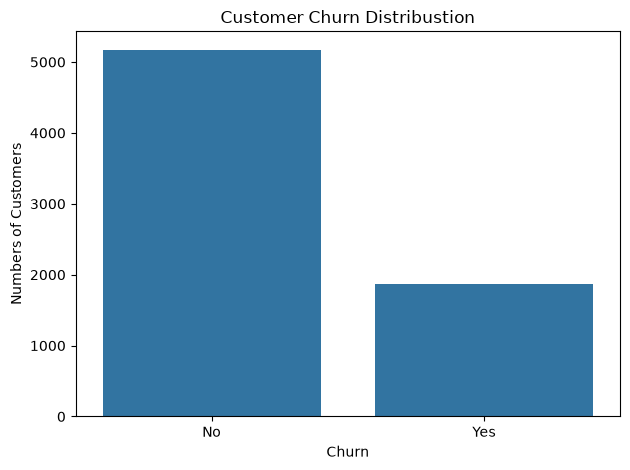

In [24]:
# Visualise Customer Chnur
sns.countplot(data=df,x="Churn")
plt.title("Customer Churn Distribustion")
plt.xlabel("Churn")
plt.ylabel("Numbers of Customers")
plt.tight_layout()
plt.show()

In [25]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

# 8. Analyze important features

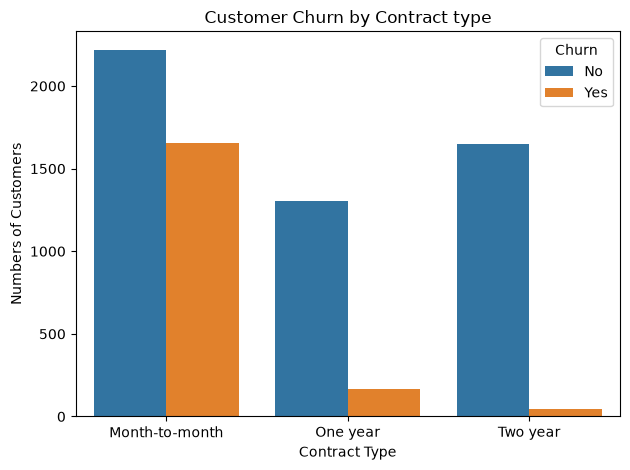

In [29]:
sns.countplot(data=df,x="Contract",hue="Churn")
plt.title("Customer Churn by Contract type")
plt.xlabel("Contract Type")
plt.ylabel("Numbers of Customers")
plt.tight_layout()
plt.show()

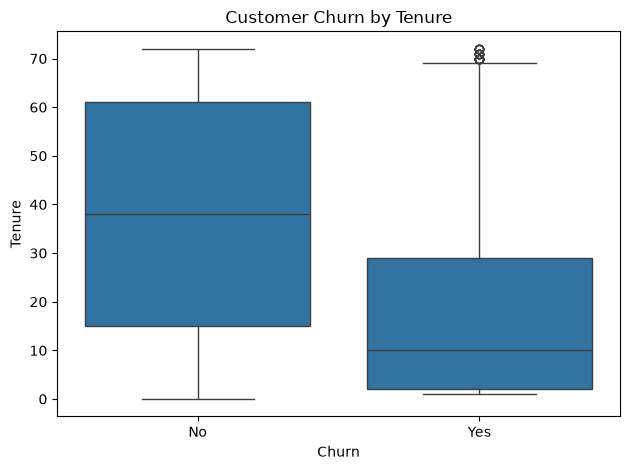

In [30]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Churn by Tenure")
plt.xlabel("Churn")
plt.ylabel("Tenure")
plt.tight_layout()
plt.show()
plt.show()

# 9. Data Prepration

In [32]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

print(df["TotalCharges"].isnull().sum())

11


In [34]:
# Handle null values 
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
print(df["TotalCharges"].isnull().sum())

0


In [36]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [38]:
df = df.drop(columns=["customerID"])

X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No":0,"Yes":1})

print("X shape : ",X.shape)
print("y shape : ",y.shape)

X shape :  (7043, 19)
y shape :  (7043,)


# 10. Spliting data into training and testing

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print("X train shape : ",X_train.shape)
print("X test shape : ",X_test.shape)
print("y train shape : ",y_train.shape)
print("y test shape : ",y_test.shape)


X train shape :  (5634, 19)
X test shape :  (1409, 19)
y train shape :  (5634,)
y test shape :  (1409,)


In [40]:
print(df.dtypes)

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


# 11. Processing the data

In [44]:
num_cols = X.select_dtypes(include=["float64","int64"]).columns
cat_cols = X.select_dtypes(include=["str","object","category"]).columns

print("List of numerical columns : ",list(num_cols))
print("\nList of categorical columns : ",list(cat_cols))

List of numerical columns :  ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

List of categorical columns :  ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [45]:
# Creating pipeline
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])



# 12. Train the logistic regression model

In [46]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [47]:
# Make Prediction
y_pred = lr_model.predict(X_test)

In [52]:
# Model Evaluation
print("Model Evaluation Logistic Regression Model :\n")
print("Accuracy Score of model : ",accuracy_score(y_test, y_pred))
print("\nClassification Report : \n",classification_report(y_test, y_pred))
print("\nConfusion Matrix : \n",confusion_matrix(y_test, y_pred))

Model Evaluation Logistic Regression Model :

Accuracy Score of model :  0.8211497515968772

Classification Report : 
               precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409


Confusion Matrix : 
 [[933 103]
 [149 224]]


# 13. Train the Random Forest Model

In [57]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [58]:
# Make Prediction
y_pred_rf = rf_model.predict(X_test)

In [59]:
# Model Evaluation
print("Model Evaluation Random Forest Classifier :\n")
print("Accuracy Score of model : ",accuracy_score(y_test, y_pred_rf))
print("\nClassification Report : \n",classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix : \n",confusion_matrix(y_test, y_pred_rf))

Model Evaluation Random Forest Classifier :

Accuracy Score of model :  0.7970191625266146

Classification Report : 
               precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.47      0.55       373

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.71      1409
weighted avg       0.78      0.80      0.79      1409


Confusion Matrix : 
 [[946  90]
 [196 177]]


# 14. Compare Losistic Regression and Random forest

In [64]:
models = {
    "Logistic Regression" : (lr_model, y_pred),
    "Random Forest Classifier" : (rf_model, y_pred_rf)
}

for name, (model, pred) in models.items():
    proba = model.predict_proba(X_test)[:, 1]

    print("\n",name)
    print("Accuracy Score :", round(accuracy_score(y_test,pred), 3))
    print("Precision Score :", round(precision_score(y_test,pred), 3))
    print("Recall Score :", round(recall_score(y_test,pred), 3))
    print("F1 Score :", round(f1_score(y_test,pred), 3))
    print("ROC-AUC Score :", round(roc_auc_score(y_test,proba), 3))


 Logistic Regression
Accuracy Score : 0.821
Precision Score : 0.685
Recall Score : 0.601
F1 Score : 0.64
ROC-AUC Score : 0.862

 Random Forest Classifier
Accuracy Score : 0.797
Precision Score : 0.663
Recall Score : 0.475
F1 Score : 0.553
ROC-AUC Score : 0.835


<h3>Logistic Regression performs much better than random forest model

# 15. Save the models

In [67]:
import joblib

joblib.dump(lr_model, "Customer_Churn_Logistic_Regression_Model.pkl")
joblib.dump(rf_model, "Customer_Churn_Random_Forest_Model.pkl")

print("Model Saved Sucessfully")

Model Saved Sucessfully


# 16. Test the model with New customers

In [70]:
import joblib

model_1 = joblib.load("Customer_Churn_Logistic_Regression_Model.pkl")
model_2 = joblib.load("Customer_Churn_Random_Forest_Model.pkl")

print("Model loaded Sucessfully")

Model loaded Sucessfully


In [71]:
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 75.0,
    "TotalCharges": 150.0
}])

<h3>Test Logistic Regression Model

In [74]:
prediction = model_1.predict(new_customer)[0]
probability = model_1.predict_proba(new_customer)[0][1]

if prediction == 1:
    print("Prediction : Customer May Churn")

else:
    print("Prediction : Customer may Stay or not Chur")

print("\nChurn Probability : ",round(probability*100, 2), "%")  

Prediction : Customer May Churn

Churn Probability :  67.73 %


<h3>Test Random Forest Model

In [75]:
prediction_2 = model_2.predict(new_customer)[0]
probability_2 = model_2.predict_proba(new_customer)[0][1]

if prediction_2 == 1:
    print("Prediction : Customer May Churn")

else:
    print("Prediction : Customer may Stay or not Chur")

print("\nChurn Probability : ",round(probability_2*100, 2), "%")  

Prediction : Customer May Churn

Churn Probability :  74.0 %


 <h3>Another Example

In [94]:
new_customer = pd.DataFrame([{
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "Yes",
    "tenure": 10,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Two Year",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 75.0,
    "TotalCharges": 150.0
}])

In [95]:
print("Logistic Regression Model Prediction : ")
prediction = model_1.predict(new_customer)[0]
probability = model_1.predict_proba(new_customer)[0][1]

if prediction == 1:
    print("Prediction : Customer May Churn")

else:
    print("Prediction : Customer may Stay or not Chur")

print("Churn Probability : ",round(probability*100, 2), "%")  

print("\nRandom Forest Classifier Model Prediction : ")

prediction_2 = model_2.predict(new_customer)[0]
probability_2 = model_2.predict_proba(new_customer)[0][1]

if prediction_2 == 1:
    print("Prediction : Customer May Churn")

else:
    print("Prediction : Customer may Stay or not Chur")

print("Churn Probability : ",round(probability_2*100, 2), "%") 

Logistic Regression Model Prediction : 
Prediction : Customer may Stay or not Chur
Churn Probability :  39.0 %

Random Forest Classifier Model Prediction : 
Prediction : Customer may Stay or not Chur
Churn Probability :  37.0 %
